# VTA 逐簇物种差异表达分析

沿用指定整合对象的既有共同基因名及用户热图簇配对，不重新进行同源映射或表达相关性配对。

- 主分析：按 species × individual × cluster 汇总 RNA 原始计数，逐簇对使用 edgeR 拟合 `~ species`。
- 敏感性分析：全量猴细胞，使用同样的 `~ species` 模型；全量猴细胞不替代主分析输入。
- 正 log2FC 表示猴较高；差异阈值为逐簇对 FDR < 0.05 且 |log2FC| ≥ 1，并补充跨簇对统一 BH 校正。
- DA_4、DA_5 的一对多关系分别比较；DA_8 保留弱对应；DA_6 不配对。

前半部分计算并导出 DEG，末尾使用已导出的主分析结果筛选代表基因，绘制逐簇对堆叠小提琴图。请使用 R 内核按顺序运行。DEG 需要 Seurat、Matrix、edgeR（robust 拟合需要 statmod）；绘图还需要 ggplot2、patchwork、ragg 和 svglite。所有输出使用参数单元中的 `out` 路径，绘图不会重新拟合 DEG。


In [2]:
# 参数：沿用用户既有基因对应和热图配对
suppressPackageStartupMessages({
  library(Seurat)
  library(Matrix)
  library(edgeR)
})
root <- '/mnt/90-connectome/Personal/CQW/midbrain'
out <- file.path(root, 'analysis/cluster_species_deg_heatmap_20261101_new')
dir.create(out, recursive = TRUE, showWarnings = FALSE)
for (d in c('tables', 'deg')) dir.create(file.path(out, d), showWarnings = FALSE)
write_table <- function(x, name) write.csv(x, file.path(out, 'tables', paste0(name, '.csv')), row.names = FALSE, na = '', fileEncoding = 'UTF-8')
fdr_cutoff <- 0.05
lfc_cutoff <- 1


In [3]:
# 直接读取用户指定对象的 RNA counts，不重新匹配或筛选同源基因
input <- file.path(root, 'datasets/Macaque_Rat_DA_integrated_data_new.rds')
x <- readRDS(input)
mc <- LayerData(x, assay = 'RNA', layer = 'counts.2')
rc <- LayerData(x, assay = 'RNA', layer = 'counts.1')
stopifnot(all(x@meta.data[colnames(mc), 'species'] == 'macaque'), all(x@meta.data[colnames(rc), 'species'] == 'rat'))
stopifnot(!anyDuplicated(rownames(mc)), !anyDuplicated(rownames(rc)))
genes <- intersect(rownames(mc), rownames(rc))
counts <- cbind(mc[genes, ], rc[genes, ])
meta <- x@meta.data[colnames(counts), c('species', 'Animal', 'cluster')]
names(meta)[2] <- 'individual'
meta$cell <- rownames(meta)
stopifnot(!anyNA(meta), all(counts@x >= 0), all(counts@x == round(counts@x)))
write_table(data.frame(gene = genes), 'existing_mapped_genes_used')
write_table(data.frame(species = c('macaque', 'rat'), original_assay_genes = c(nrow(mc), nrow(rc)), shared_existing_genes = length(genes), cells = c(ncol(mc), ncol(rc))), 'input_summary')
write_table(data.frame(species = c(rep('macaque', nrow(mc)), rep('rat', nrow(rc))), gene = c(rownames(mc), rownames(rc)), shared_existing_gene = c(rownames(mc) %in% genes, rownames(rc) %in% genes)), 'feature_presence')
write_table(meta, 'cell_metadata')
cat('沿用既有共同基因:', length(genes), '猴细胞:', ncol(mc), '大鼠细胞:', ncol(rc), '\n'); flush.console()


沿用既有共同基因: 13846 猴细胞: 400 大鼠细胞: 399 


In [4]:
# 按热图确定对应；一对多分别比较，DA_8保留弱对应，DA_6不配对
pairs <- data.frame(
  pair_id = c('M0_R1', 'M1_R3', 'M2_R5', 'M3_R2', 'M4_R4', 'M4_R6', 'M5_R0', 'M5_R7', 'M7_R3', 'M8_R3'),
  macaque_cluster = paste0('DA_', c(0, 1, 2, 3, 4, 4, 5, 5, 7, 8)),
  rat_cluster = paste0('DA_', c(1, 3, 5, 2, 4, 6, 0, 7, 3, 3)),
  heatmap_note = c('Primary heatmap match', 'Primary heatmap match', 'Primary heatmap match', 'Primary heatmap match', 'One-to-many heatmap match', 'One-to-many heatmap match', 'One-to-many heatmap match', 'One-to-many heatmap match', 'Primary heatmap match', 'Weak heatmap match'),
  stringsAsFactors = FALSE
)
write_table(pairs, 'heatmap_cluster_pairs')
write_table(data.frame(macaque_cluster = 'DA_6', reason = '热图中无对应大鼠cluster，不进行簇对物种DEG'), 'unpaired_cluster')


In [5]:
# Species × Individual × Cluster 对原始计数求和
aggregate_pb <- function(counts, meta) {
  key <- paste(meta$species, meta$individual, meta$cluster, sep = '__')
  ids <- unique(key)
  membership <- sparseMatrix(i = seq_along(key), j = match(key, ids), x = 1)
  pb <- as.matrix(counts %*% membership)
  colnames(pb) <- ids
  info <- meta[match(ids, key), c('species', 'individual', 'cluster')]
  rownames(info) <- ids
  info$n_cells <- tabulate(match(key, ids), nbins = length(ids))
  info$raw_library_counts <- colSums(pb)
  stopifnot(sum(pb) == sum(counts))
  list(counts = pb, info = info)
}
pb <- aggregate_pb(counts, meta)
write_table(cbind(pseudobulk_id = rownames(pb$info), pb$info), 'pseudobulk_samples')
write_table(cbind(gene = rownames(pb$counts), as.data.frame(pb$counts, check.names = FALSE)), 'pseudobulk_counts')


In [6]:
# 全量猴细胞仅作补充敏感性分析，主分析严格使用指定整合对象
monkey_full <- readRDS(file.path(root, 'datasets/Macaque_VTA_DA_cluster.rds'))
full_mc <- LayerData(monkey_full, assay = 'RNA', layer = 'counts')
stopifnot(all(genes %in% rownames(full_mc)), all(monkey_full@meta.data[colnames(mc), 'cluster'] == meta[colnames(mc), 'cluster']))
stopifnot(all(full_mc[genes, colnames(mc)] == mc[genes, ]))
full_meta <- data.frame(species = 'macaque', individual = monkey_full$Animal, cluster = monkey_full$cluster, cell = colnames(monkey_full), row.names = colnames(monkey_full))
full_meta <- rbind(full_meta, meta[meta$species == 'rat', ])
pb_full <- aggregate_pb(cbind(full_mc[genes, ], rc[genes, ]), full_meta)
saveRDS(list(main = pb, full_macaque_sensitivity = pb_full), file.path(out, 'pseudobulk_counts.rds'))


In [7]:
# edgeR：每个簇对独立拟合；正logFC表示猴较高
fit_pair <- function(pb, pair, analysis) {
  info <- pb$info
  keep_sample <- (info$species == 'macaque' & info$cluster == pair$macaque_cluster) | (info$species == 'rat' & info$cluster == pair$rat_cluster)
  info <- info[keep_sample, , drop = FALSE]
  info$species <- factor(info$species, levels = c('rat', 'macaque'))
  design <- model.matrix(~ species, info)
  stopifnot(qr(design)$rank == ncol(design), all(table(info$species) >= 2))
  y <- DGEList(pb$counts[, keep_sample], samples = info)
  keep_gene <- filterByExpr(y, design = design, min.count = 10, min.total.count = 15)
  y <- calcNormFactors(y[keep_gene, , keep.lib.sizes = FALSE])
  y <- estimateDisp(y, design, robust = TRUE)
  fit <- glmQLFit(y, design, robust = TRUE)
  tab <- topTags(glmQLFTest(fit, coef = 'speciesmacaque'), n = Inf)$table
  tab <- cbind(gene = rownames(tab), tab)
  tab$pair_id <- pair$pair_id
  tab$analysis <- analysis
  tab$direction <- ifelse(tab$FDR < fdr_cutoff & tab$logFC >= lfc_cutoff, 'macaque_higher', ifelse(tab$FDR < fdr_cutoff & tab$logFC <= -lfc_cutoff, 'rat_higher', 'below_threshold'))
  tab$heatmap_note <- pair$heatmap_note
  values <- cpm(y, normalized.lib.sizes = TRUE, log = TRUE, prior.count = 2)
  write_table(cbind(gene = rownames(values), as.data.frame(values, check.names = FALSE)), paste0('logCPM_', analysis, '__', pair$pair_id))
  dm <- cbind(pseudobulk_id = rownames(info), info, as.data.frame(design, check.names = FALSE), TMM_factor = y$samples$norm.factors, effective_library_size = y$samples$lib.size * y$samples$norm.factors)
  write_table(dm, paste0('design_', analysis, '__', pair$pair_id))
  write_table(data.frame(gene = genes, tested = keep_gene), paste0('gene_filter_', analysis, '__', pair$pair_id))
  write.csv(tab, file.path(out, 'deg', paste0(analysis, '__', pair$pair_id, '.csv')), row.names = FALSE, fileEncoding = 'UTF-8')
  summary <- data.frame(pair_id = pair$pair_id, analysis = analysis, genes_tested = nrow(tab), macaque_higher = sum(tab$direction == 'macaque_higher'), rat_higher = sum(tab$direction == 'rat_higher'), macaque_cells = sum(info$n_cells[info$species == 'macaque']), rat_cells = sum(info$n_cells[info$species == 'rat']), rat_min_cells = min(info$n_cells[info$species == 'rat']), macaque_samples = sum(info$species == 'macaque'), rat_pools = sum(info$species == 'rat'), residual_df = nrow(design) - ncol(design))
  list(table = tab, summary = summary)
}


In [8]:
# 运行主分析与全量猴细胞敏感性分析，汇总并补充跨簇对BH校正
results <- list()
for (i in seq_len(nrow(pairs))) {
  pr <- pairs[i, ]
  cat('正在分析:', pr$pair_id, '\n'); flush.console()
  results[[paste('main', pr$pair_id)]] <- fit_pair(pb, pr, 'main')
  results[[paste('full_macaque', pr$pair_id)]] <- fit_pair(pb_full, pr, 'full_macaque')
}
summary <- do.call(rbind, lapply(results, `[[`, 'summary'))
write_table(summary, 'DEG_summary_all_analyses')
main <- do.call(rbind, lapply(results[startsWith(names(results), 'main ')], `[[`, 'table'))
main$FDR_across_pairs <- p.adjust(main$PValue, 'BH')
write_table(main, 'main_DEG_all_tested_genes')
write_table(main[main$direction != 'below_threshold', ], 'main_DEG_significant')
for (id in pairs$pair_id) write.csv(main[main$pair_id == id, ], file.path(out, 'deg', paste0('main__', id, '.csv')), row.names = FALSE, fileEncoding = 'UTF-8')


正在分析: M0_R1 


正在分析: M1_R3 
正在分析: M2_R5 
正在分析: M3_R2 
正在分析: M4_R4 
正在分析: M4_R6 
正在分析: M5_R0 
正在分析: M5_R7 
正在分析: M7_R3 
正在分析: M8_R3 


In [9]:
# 敏感性按基因合并，不另用表达相关性决定cluster配对
combined <- list()
for (id in pairs$pair_id) {
  z <- main[main$pair_id == id, ]
  s <- results[[paste('full_macaque', id)]]$table
  idx <- match(z$gene, s$gene)
  z$full_macaque_logFC <- s$logFC[idx]
  z$full_macaque_FDR <- s$FDR[idx]
  combined[[id]] <- z
}
combined <- do.call(rbind, combined)
write_table(combined, 'main_DEG_with_sensitivity')
main_summary <- merge(summary[summary$analysis == 'main', ], pairs, by = 'pair_id', sort = FALSE)
main_summary <- main_summary[match(pairs$pair_id, main_summary$pair_id), ]
write_table(main_summary, 'main_DEG_summary')
print(main_summary)
cat('差异基因计算完成:', out, '\n')


   pair_id analysis genes_tested macaque_higher rat_higher macaque_cells
1    M0_R1     main         4404           1062       1040            74
2    M1_R3     main         4929           1225       1168            76
3    M2_R5     main         3549            863        791            57
4    M3_R2     main         3093            755        718            37
5    M4_R4     main         4181            964        936            46
6    M4_R6     main         1759            431        402            46
7    M5_R0     main         3760            861        854            35
8    M5_R7     main          767            186        163            35
9    M7_R3     main         4935           1170       1172            26
10   M8_R3     main         4164            648        689            23
   rat_cells rat_min_cells macaque_samples rat_pools residual_df
1         61            10               2         4           4
2         60            12               2         4           4
3 

In [22]:
main_summary

,pair_id,analysis,genes_tested,macaque_higher,rat_higher,macaque_cells,rat_cells,rat_min_cells,macaque_samples,rat_pools,residual_df,macaque_cluster,rat_cluster,heatmap_note
,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<chr>,<chr>,<chr>
1,M0_R1,main,4404,1062,1040,74,61,10,2,4,4,DA_0,DA_1,热图主要对应
2,M1_R3,main,4929,1225,1168,76,60,12,2,4,4,DA_1,DA_3,热图主要对应
3,M2_R5,main,3549,863,791,57,40,6,2,4,4,DA_2,DA_5,热图主要对应
4,M3_R2,main,3093,755,718,37,61,9,2,4,4,DA_3,DA_2,热图主要对应
5,M4_R4,main,4181,964,936,46,46,5,2,4,4,DA_4,DA_4,热图一对多
6,M4_R6,main,1759,431,402,46,34,6,2,4,4,DA_4,DA_6,热图一对多
7,M5_R0,main,3760,861,854,35,69,14,2,4,4,DA_5,DA_0,热图一对多
8,M5_R7,main,767,186,163,35,16,1,2,4,4,DA_5,DA_7,热图一对多
9,M7_R3,main,4935,1170,1172,26,60,12,2,4,4,DA_7,DA_3,热图主要对应


## 对应簇对的差异基因与保守候选表达

每个簇对分别选择猴较高 5 个、保守候选 5 个、大鼠较高 5 个基因。差异基因满足主分析逐簇对 FDR < 0.05 且 |log2FC| ≥ 1，按各方向的差异幅度从大到小排序；并列时优先较小 FDR。保守候选满足 FDR ≥ 0.05、|log2FC| ≤ 0.25，且两物种各至少 25% 的细胞原始计数 > 0，按 |log2FC| 从小到大排序；并列时优先较高 logCPM。候选不足时明确警告，只显示实际符合条件的基因，不放宽阈值。

**保守候选不是统计等效性检验的结论。** 小提琴展示主分析单细胞的 `log1p(count / 该细胞全部共同基因的计数和 × 10000)`，保留零表达细胞，不使用 integrated 表达或 pseudobulk logCPM。每个基因单独设置纵轴；同一基因的猴与大鼠共用纵轴。小提琴宽度归一化，不表示细胞数量；细胞级分布仅作展示，不重新做细胞级显著性检验，细胞多的个体对分布贡献更大。

默认所有簇对横向放在同一行，并分别保存单图和总图（PNG/SVG），同时导出选基因、候选数量及绘图表达表。重启内核后只需先运行参数、输入计数和簇配对单元，再运行以下单元；主分析 DEG 直接从当前 `out` 中的已导出结果读取，无需重新运行 edgeR。


In [10]:
suppressPackageStartupMessages({
  library(ggplot2)
  library(patchwork)
})
violin_top_n <- 5L
conserved_lfc_max <- 0.25
conserved_detection_min <- 0.25
# violin_ncol <- nrow(pairs)
violin_ncol <- 5L
violin_pair_width <- 6
violin_font <- 'Noto Sans CJK SC'
violin_categories <- c('macaque_higher', 'conserved_candidate', 'rat_higher')
violin_colors <- c(macaque_higher = '#dd806b', conserved_candidate = '#8ab16d', rat_higher = '#69a5b7')
violin_labels <- c(macaque_higher = 'Higher in macaque', conserved_candidate = 'Conserved candidates', rat_higher = 'Higher in rat')
plot_deg <- read.csv(file.path(out, 'tables', 'main_DEG_all_tested_genes.csv'), check.names = FALSE)
stopifnot(all(c('gene', 'pair_id', 'logFC', 'logCPM', 'FDR') %in% names(plot_deg)),
          !anyDuplicated(paste(plot_deg$pair_id, plot_deg$gene)),
          all(is.finite(plot_deg$logFC)), all(is.finite(plot_deg$logCPM)),
          all(is.finite(plot_deg$FDR)), all(plot_deg$FDR >= 0 & plot_deg$FDR <= 1),
          all(plot_deg$gene %in% rownames(counts)), all(pairs$pair_id %in% plot_deg$pair_id),
          identical(colnames(counts), rownames(meta)), !anyNA(meta),
          violin_top_n >= 1L, violin_ncol >= 1L, violin_ncol <= nrow(pairs))
cell_library <- Matrix::colSums(counts)
if (any(!is.finite(cell_library) | cell_library <= 0)) stop('主分析中存在共同基因计数和为零或非有限值的细胞，无法计算 CP10K。')
dir.create(file.path(out, 'figures'), showWarnings = FALSE)


In [11]:
select_violin_genes <- function(pair, deg, counts, meta) {
  z <- deg[deg$pair_id == pair$pair_id, , drop = FALSE]
  macaque_cells <- which(meta$species == 'macaque' & meta$cluster == pair$macaque_cluster)
  rat_cells <- which(meta$species == 'rat' & meta$cluster == pair$rat_cluster)
  if (!length(macaque_cells) || !length(rat_cells)) stop(paste('簇对缺少主分析细胞：', pair$pair_id))
  z$macaque_detected_fraction <- as.numeric(Matrix::rowMeans(counts[z$gene, macaque_cells, drop = FALSE] > 0))
  z$rat_detected_fraction <- as.numeric(Matrix::rowMeans(counts[z$gene, rat_cells, drop = FALSE] > 0))
  eligible <- list(
    macaque_higher = z[z$FDR < fdr_cutoff & z$logFC >= lfc_cutoff, , drop = FALSE],
    conserved_candidate = z[z$FDR >= fdr_cutoff & abs(z$logFC) <= conserved_lfc_max &
      z$macaque_detected_fraction >= conserved_detection_min & z$rat_detected_fraction >= conserved_detection_min, , drop = FALSE],
    rat_higher = z[z$FDR < fdr_cutoff & z$logFC <= -lfc_cutoff, , drop = FALSE]
  )
  eligible$macaque_higher <- eligible$macaque_higher[order(-eligible$macaque_higher$logFC, eligible$macaque_higher$FDR, eligible$macaque_higher$gene), , drop = FALSE]
  eligible$conserved_candidate <- eligible$conserved_candidate[order(abs(eligible$conserved_candidate$logFC), -eligible$conserved_candidate$logCPM, eligible$conserved_candidate$gene), , drop = FALSE]
  eligible$rat_higher <- eligible$rat_higher[order(eligible$rat_higher$logFC, eligible$rat_higher$FDR, eligible$rat_higher$gene), , drop = FALSE]
  selected <- lapply(violin_categories, function(category) {
    candidates <- eligible[[category]]
    if (nrow(candidates) < violin_top_n) warning(sprintf('%s：%s 仅有 %d 个符合条件的基因（要求 %d 个），不放宽阈值。', pair$pair_id, violin_labels[[category]], nrow(candidates), violin_top_n), call. = FALSE)
    chosen <- head(candidates, violin_top_n)
    chosen$category <- rep(category, nrow(chosen))
    chosen$category_rank <- seq_len(nrow(chosen))
    chosen
  })
  availability <- data.frame(pair_id = pair$pair_id, category = violin_categories,
    eligible_genes = vapply(eligible[violin_categories], nrow, integer(1)), requested_genes = violin_top_n,
    selected_genes = vapply(selected, nrow, integer(1)), row.names = NULL)
  list(selected = do.call(rbind, selected), availability = availability)
}
violin_selection <- lapply(seq_len(nrow(pairs)), function(i) select_violin_genes(pairs[i, ], plot_deg, counts, meta))
violin_genes <- do.call(rbind, lapply(violin_selection, `[[`, 'selected'))
violin_availability <- do.call(rbind, lapply(violin_selection, `[[`, 'availability'))
if (!nrow(violin_genes)) stop('全部簇对均无满足条件的基因，请检查 DEG 与筛选阈值；未生成图像。')
stopifnot(!anyDuplicated(paste(violin_genes$pair_id, violin_genes$gene)))
write_table(violin_genes, 'violin_selected_genes')
write_table(violin_availability, 'violin_gene_availability')
print(violin_availability)


   pair_id            category eligible_genes requested_genes selected_genes
1    M0_R1      macaque_higher           1062               5              5
2    M0_R1 conserved_candidate            651               5              5
3    M0_R1          rat_higher           1040               5              5
4    M1_R3      macaque_higher           1225               5              5
5    M1_R3 conserved_candidate            715               5              5
6    M1_R3          rat_higher           1168               5              5
7    M2_R5      macaque_higher            863               5              5
8    M2_R5 conserved_candidate            578               5              5
9    M2_R5          rat_higher            791               5              5
10   M3_R2      macaque_higher            755               5              5
11   M3_R2 conserved_candidate            486               5              5
12   M3_R2          rat_higher            718               5              5

In [12]:
build_violin_expression <- function(pair, selected, counts, meta, cell_library) {
  chosen <- selected[selected$pair_id == pair$pair_id, , drop = FALSE]
  cells <- which((meta$species == 'macaque' & meta$cluster == pair$macaque_cluster) |
    (meta$species == 'rat' & meta$cluster == pair$rat_cluster))
  if (!nrow(chosen)) return(data.frame(pair_id = character(), gene = character(), category = character(), cell = character(), individual = character(), species = character(), expression = numeric()))
  raw <- as.matrix(counts[chosen$gene, cells, drop = FALSE])
  values <- log1p(sweep(raw, 2, cell_library[cells], '/') * 10000)
  data.frame(pair_id = pair$pair_id, gene = rep(chosen$gene, times = length(cells)),
    category = rep(chosen$category, times = length(cells)), cell = rep(colnames(counts)[cells], each = nrow(chosen)),
    individual = rep(meta$individual[cells], each = nrow(chosen)), species = rep(meta$species[cells], each = nrow(chosen)),
    expression = as.vector(values))
}
violin_expression <- do.call(rbind, lapply(seq_len(nrow(pairs)), function(i) build_violin_expression(pairs[i, ], violin_genes, counts, meta, cell_library)))
stopifnot(all(is.finite(violin_expression$expression)), all(violin_expression$expression >= 0),
          !anyDuplicated(paste(violin_expression$pair_id, violin_expression$gene, violin_expression$cell)))
write_table(violin_expression, 'violin_cell_expression')


In [39]:
pairs

pair_id,macaque_cluster,rat_cluster,heatmap_note
<chr>,<chr>,<chr>,<chr>
M0_R1,DA_0,DA_1,热图主要对应
M1_R3,DA_1,DA_3,热图主要对应
M2_R5,DA_2,DA_5,热图主要对应
M3_R2,DA_3,DA_2,热图主要对应
M4_R4,DA_4,DA_4,热图一对多
M4_R6,DA_4,DA_6,热图一对多
M5_R0,DA_5,DA_0,热图一对多
M5_R7,DA_5,DA_7,热图一对多
M7_R3,DA_7,DA_3,热图主要对应


In [13]:
make_pair_violin <- function(pair, selected, expression) {
  chosen <- selected[selected$pair_id == pair$pair_id, , drop = FALSE]
  title <- paste('Macaque', pair$macaque_cluster, 'vs Rat', pair$rat_cluster)
  if (!nrow(chosen)) {
    return(ggplot() + annotate('text', x = 0, y = 0, label = 'No candidate genes meet the thresholds', family = violin_font) +
      labs(title = title) + theme_void(base_family = violin_font))
  }
  d <- expression[expression$pair_id == pair$pair_id, , drop = FALSE]
  d$gene <- factor(d$gene, levels = chosen$gene)
  d$species <- factor(d$species, levels = c('macaque', 'rat'))
  d$category <- factor(d$category, levels = violin_categories)
  d$x <- as.integer(d$species)
  groups <- split(seq_len(nrow(d)), interaction(d$gene, d$species, drop = TRUE))
  constant <- vapply(groups, function(rows) length(rows) < 2L || all(d$expression[rows] == d$expression[rows[1]]), logical(1))
  density_rows <- unlist(groups[!constant], use.names = FALSE)
  constant_rows <- vapply(groups[constant], function(rows) rows[1], integer(1))
  counts_label <- paste0('Macaque cells: ', sum(!duplicated(d$cell[d$species == 'macaque'])), '; Rat cells: ', sum(!duplicated(d$cell[d$species == 'rat'])))
  ggplot(d, aes(x, expression)) +
    geom_hline(yintercept = 0, color = '#d9d9d9', linewidth = 0.2) +
    geom_violin(data = d[density_rows, , drop = FALSE], aes(fill = category, group = interaction(gene, species)),
      scale = 'width', trim = TRUE, width = 0.85, color = '#62676d', linewidth = 0.3, show.legend = TRUE) +
    geom_segment(data = d[constant_rows, , drop = FALSE], aes(x = x - 0.35, xend = x + 0.35,
      y = expression, yend = expression, color = category), inherit.aes = FALSE, linewidth = 0.6, show.legend = FALSE) +
    facet_grid(rows = vars(gene), scales = 'free_y', drop = FALSE, switch = 'y') +
    scale_x_continuous(breaks = c(1, 2), labels = c(paste('Macaque', pair$macaque_cluster), paste('Rat', pair$rat_cluster)), limits = c(0.5, 2.5)) +
    scale_y_continuous(limits = function(z) c(0, max(z[2], 0.1)), expand = expansion(mult = c(0, 0.08))) +
    scale_fill_manual(values = violin_colors, limits = violin_categories, breaks = violin_categories, labels = violin_labels[violin_categories], drop = FALSE) +
    scale_color_manual(values = violin_colors, limits = violin_categories, guide = 'none') +
    labs(title = title, x = NULL,
      y = 'Expression log1p(CP10K)', fill = NULL) +
    theme_classic(base_family = violin_font, base_size = 10) +
    theme(strip.background = element_blank(), strip.placement = 'outside',
      strip.text.y.left = element_text(angle = 0, face = 'bold', size = 10),
      panel.spacing.y = grid::unit(0.08, 'lines'), legend.position = 'top', legend.key.width = grid::unit(0.8, 'cm'),
      plot.title = element_text(face = 'bold', size = 14), plot.subtitle = element_text(size = 9),
      plot.caption = element_text(hjust = 0, size = 8), axis.text.x = element_text(size = 9))
}
violin_plots <- lapply(seq_len(nrow(pairs)), function(i) make_pair_violin(pairs[i, ], violin_genes, violin_expression))
names(violin_plots) <- pairs$pair_id
violin_all <- wrap_plots(violin_plots, ncol = violin_ncol, guides = 'collect') & theme(legend.position = 'top')


In [ ]:
# save_violin_plot <- function(p, name, width, height) {
#   ggsave(file.path(out, 'figures', paste0(name, '.png')), p, width = width, height = height,
#     units = 'in', dpi = 180, device = ragg::agg_png, bg = 'white', limitsize = FALSE)
#   ggsave(file.path(out, 'figures', paste0(name, '.svg')), p, width = width, height = height,
#     units = 'in', device = svglite::svglite, bg = 'white', limitsize = FALSE)
# }
# violin_pair_height <- 2.6 + max(tabulate(match(violin_genes$pair_id, pairs$pair_id), nbins = nrow(pairs))) * 0.48
# for (id in pairs$pair_id) save_violin_plot(violin_plots[[id]], paste0('05_pair_violin__', id), violin_pair_width, violin_pair_height)
# violin_all_width <- violin_pair_width * violin_ncol
# violin_all_height <- violin_pair_height * ceiling(nrow(pairs) / violin_ncol)
# save_violin_plot(violin_all, '06_pair_violin_all_pairs', violin_all_width, violin_all_height)


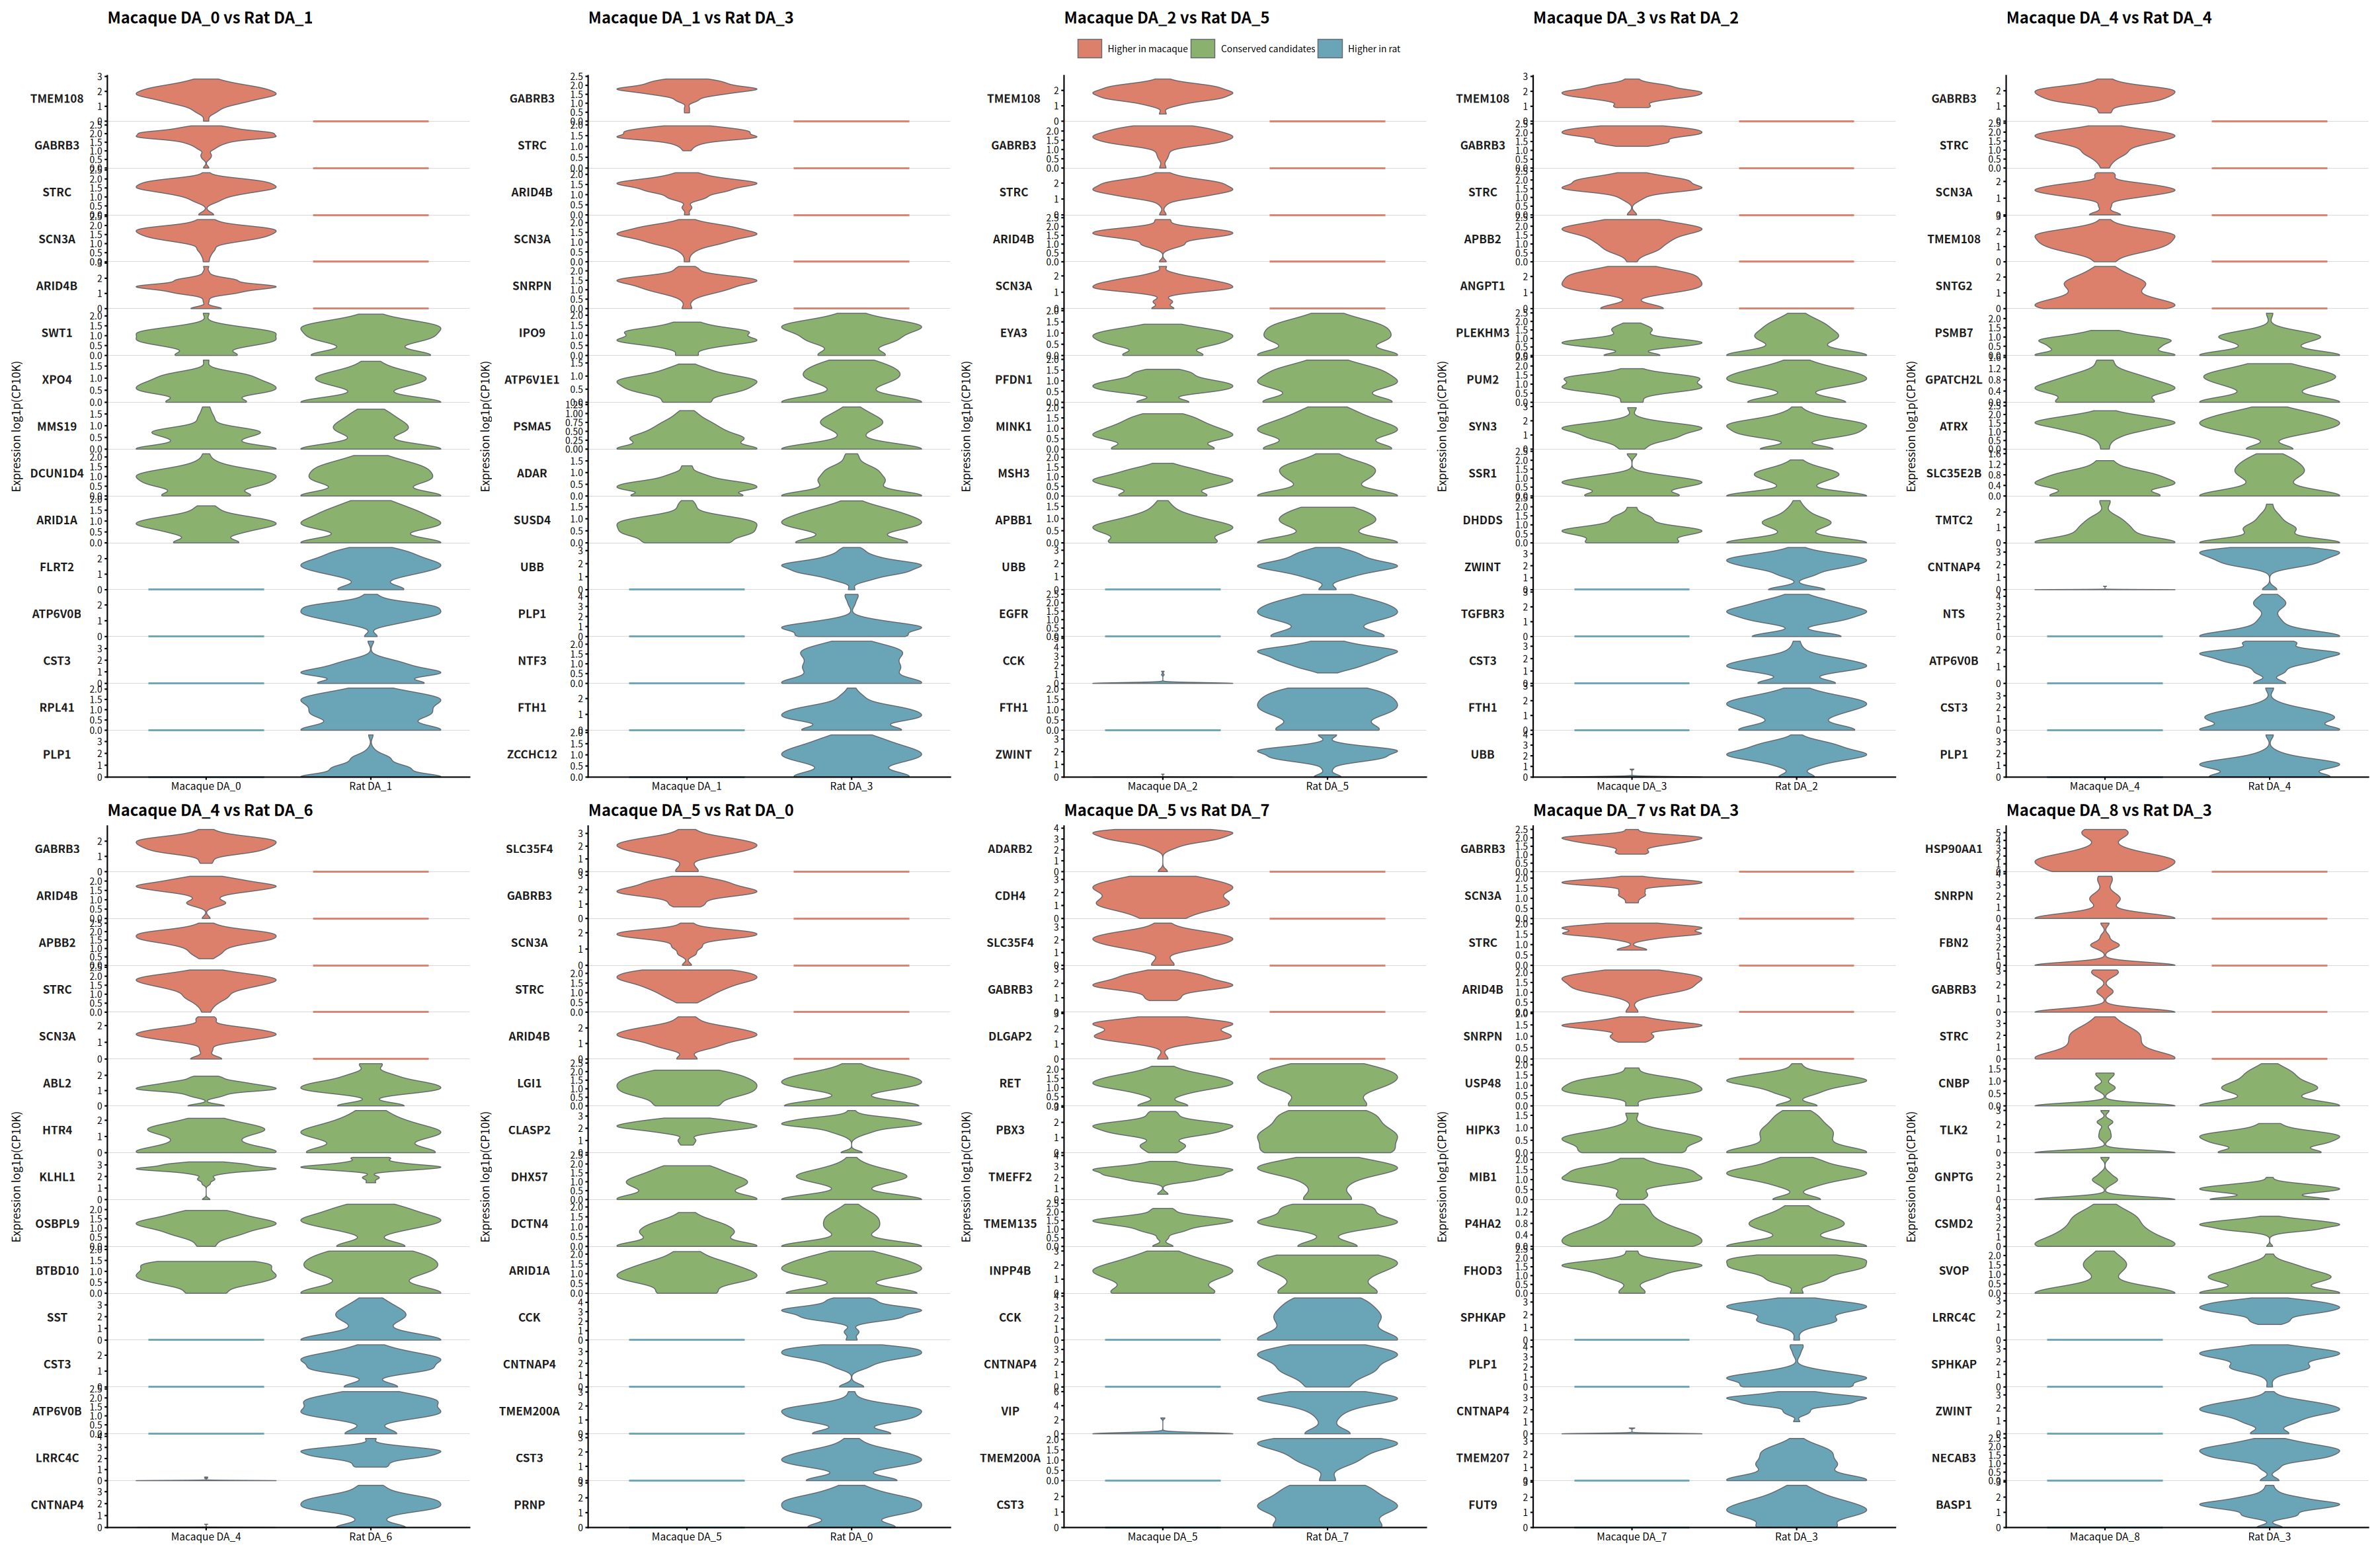

In [71]:
options(repr.plot.width = violin_all_width/2, repr.plot.height = violin_all_height*2)
print(violin_all)
# cat('小提琴图及选基因表已保存到：', out, '\n')


In [ ]:
ggsave(
  filename = '/mnt/90-connectome/Personal/CQW/midbrain/figure/vln_mq_vs_ms_DEGs.pdf',
  plot = violin_all,
  device = grDevices::cairo_pdf,
  family = violin_font,
  width = violin_all_width/2,
  height = violin_all_height * 2,
  units = 'in', bg = 'white', limitsize = FALSE
)

: 

## 10 个簇对的基因数量：韦恩式展示（2 行 × 5 列）

运行前面的 `violin-selection` 单元后，直接使用 `violin_availability$eligible_genes` 的全部候选数量，而不是每类最多 5 个的绘图选基因数量；不重新拟合 DEG。

两侧分别为猴较高和大鼠较高（沿用 FDR < 0.05、|log2FC| ≥ 1）；中间为既有筛选中的保守候选（FDR ≥ 0.05、|log2FC| ≤ 0.25，且两物种表达检出比例均 ≥ 25%）。这是三个既有类别的韦恩式示意，不是两物种表达基因集合的严格交集，也不表示物种独有基因或统计等效性。圆面积不按基因数量缩放，数字为实际数量。若修改前述筛选参数，请重新运行 `violin-selection`。

总图显示后保存为 `figures/07_pair_gene_venn_all_pairs.pdf` 和 `.png`，统计表保存为 `tables/pair_gene_venn_counts.csv`。


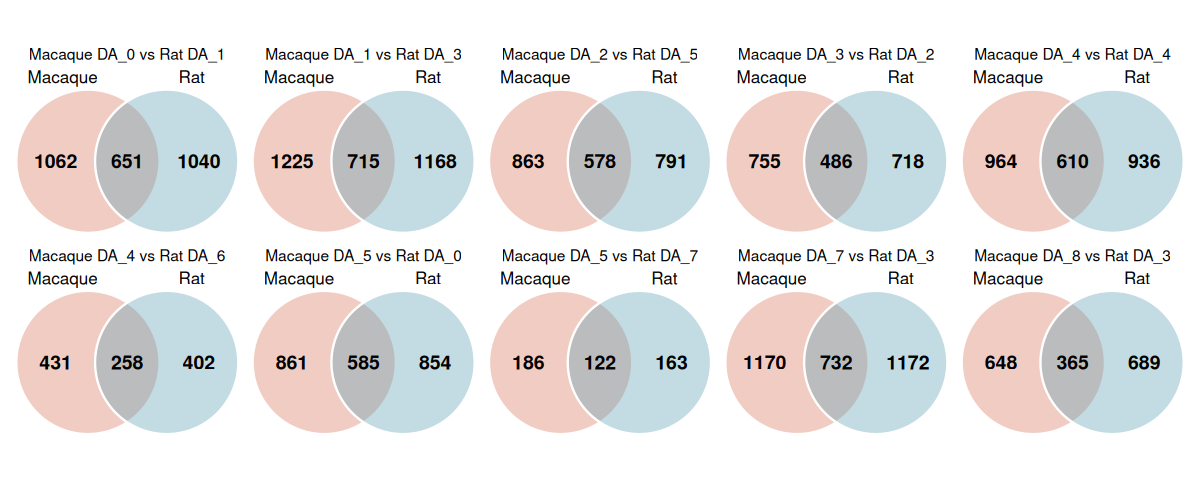

In [23]:
suppressPackageStartupMessages({
  library(ggplot2)
  library(patchwork)
})
if (!exists('violin_availability')) stop('请先运行 violin-selection 单元，生成全部候选基因数量。')
venn_categories <- c('macaque_higher', 'conserved_candidate', 'rat_higher')
stopifnot(nrow(pairs) == 10L, !anyNA(pairs$pair_id), !anyDuplicated(pairs$pair_id),
          all(c('pair_id', 'category', 'eligible_genes') %in% names(violin_availability)))
venn_availability <- violin_availability[violin_availability$pair_id %in% pairs$pair_id &
  violin_availability$category %in% venn_categories, , drop = FALSE]
stopifnot(nrow(venn_availability) == 30L, !anyNA(venn_availability),
          !anyDuplicated(paste(venn_availability$pair_id, venn_availability$category)),
          all(is.finite(venn_availability$eligible_genes)),
          all(venn_availability$eligible_genes >= 0),
          all(venn_availability$eligible_genes == floor(venn_availability$eligible_genes)))
venn_counts <- pairs[, c('pair_id', 'macaque_cluster', 'rat_cluster')]
for (category in venn_categories) {
  rows <- venn_availability[venn_availability$category == category, ]
  venn_counts[[category]] <- rows$eligible_genes[match(pairs$pair_id, rows$pair_id)]
}
stopifnot(!anyNA(venn_counts))
write_table(venn_counts, 'pair_gene_venn_counts')

venn_theta <- seq(0, 2 * pi, length.out = 361)
venn_circles <- rbind(
  data.frame(species = 'Macaque', x = -0.55 + cos(venn_theta), y = sin(venn_theta)),
  data.frame(species = 'Rat', x = 0.55 + cos(venn_theta), y = sin(venn_theta))
)
make_pair_gene_venn <- function(row) {
  labels <- data.frame(x = c(-1, 0, 1), y = 0,
    count = c(row$macaque_higher, row$conserved_candidate, row$rat_higher))
  ggplot(venn_circles, aes(x, y, group = species)) +
    geom_polygon(aes(fill = species), alpha = 0.4, colour = 'white', linewidth = 0.5) +
    geom_text(data = labels, aes(x, y, label = count), inherit.aes = FALSE,
      size = 4, fontface = 'bold') +
    annotate('text', x = c(-0.9, 0.9), y = 1.18,
      label = c('Macaque', 'Rat'), size = 3.5) +
    scale_fill_manual(values = c(Macaque = '#dd806b', Rat = '#69a5b7')) +
    coord_fixed(xlim = c(-1.65, 1.65), ylim = c(-1.1, 1.35), expand = FALSE) +
    labs(
      # title = row$pair_id,
      subtitle = paste0('Macaque ', row$macaque_cluster, ' vs Rat ', row$rat_cluster)) +
    theme_void() +
    theme(legend.position = 'none', plot.title = element_text(hjust = 0.5, face = 'bold', size = 12),
      plot.subtitle = element_text(hjust = 0.5, size = 9))
}
venn_plots <- lapply(seq_len(nrow(venn_counts)), function(i) make_pair_gene_venn(venn_counts[i, ]))
names(venn_plots) <- venn_counts$pair_id
venn_all <- wrap_plots(venn_plots, ncol = 5, nrow = 2) 
  # plot_annotation(title = 'Gene counts across 10 matched cluster pairs',
  #   subtitle = 'Left: higher in macaque | Overlap: conserved candidates | Right: higher in rat',
  #   caption = 'Schematic overlap of existing categories, not an expression-set intersection; areas are not proportional to counts.')

options(repr.plot.width = 10, repr.plot.height = 4)
print(venn_all)
dir.create(file.path(out, 'figures'), showWarnings = FALSE)
ggsave(file.path('/mnt/90-connectome/Personal/CQW/midbrain/figure/pair_gene_venn_all_pairs.pdf'), venn_all,
  width = 10, height = 4)
ggsave(file.path('/mnt/90-connectome/Personal/CQW/midbrain/figure/pair_gene_venn_all_pairs.pdf'), venn_all,
  width = 10, height = 4, dpi = 300, bg = 'white')


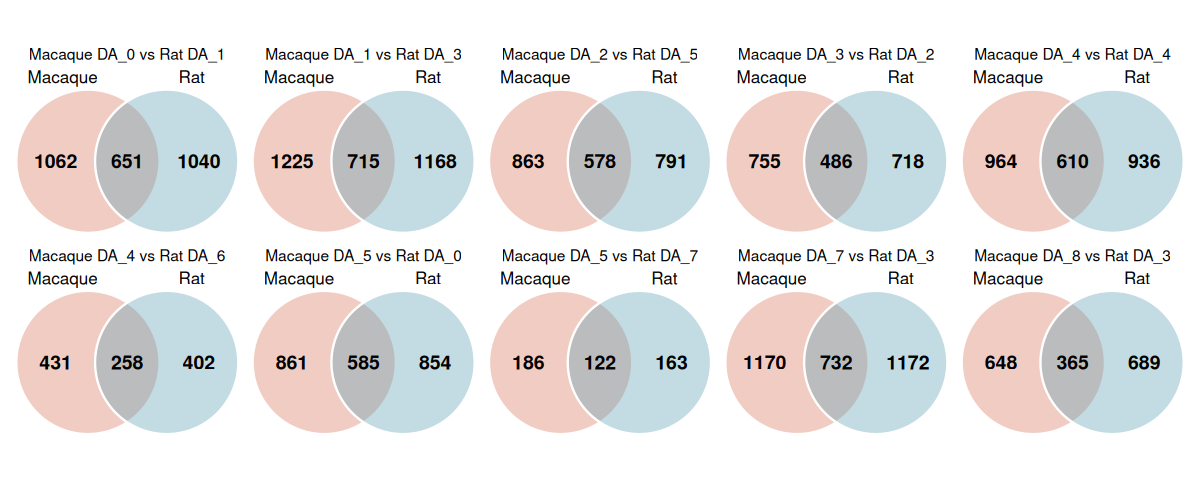

In [21]:
options(repr.plot.width = 10, repr.plot.height = 4)
print(venn_all)